# 1: Raccolta ed Esplorazione Dati

Obiettivo: scaricare una serie storica di prezzi pulita e verificata.

**Nota sulla scelta dell'asset:** uso **SPY** (ETF che replica l'S&P 500).

(1) ha oltre 30 anni di storico molto liquido

(2) riflette il mercato ampio invece di un singolo titolo

(3) l'adjusted close incorpora dividendi/split, quindi i regimi riflettono davvero il comportamento del mercato e non artefatti tecnici.

Se preferissi l'indice puro senza il tracking error dell'ETF potrei usare ^GSPC, ma perderei l'adjusted close per i dividendi, per un HMM su regimi di mercato SPY resta la scelta più solida.

## Installazione pacchetti
Installo yfinance, pandas e matplotlib.

In [1]:
# Installazione delle librerie necessarie (silenziosa con -q)
!pip install -q yfinance pandas matplotlib


## Import
Importo le librerie che useremo.

In [2]:
# Import librerie
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Formattazione dei numeri nei DataFrame stampati: 5 decimali, perché rendimenti
# e volatilità giornalieri sono dell'ordine di 0.0001-0.01 e con 2 si leggerebbe 0.00
pd.set_option('display.float_format', lambda x: f'{x:,.5f}')


## Download dei dati storici
Scarico circa 9 anni di storico giornaliero per SPY.

In [3]:
# Parametri di download
TICKER = "SPY"
END_DATE = pd.Timestamp("2026-09-23")  # la data finale è fissata per mantenere costante il periodo storico analizzato, favorendo la riproducibilità dei risultati
START_DATE = END_DATE - pd.DateOffset(years=9)  # circa 9 anni di storico

raw_data = yf.download(
    TICKER,
    start=START_DATE.strftime('%Y-%m-%d'),
    end=END_DATE.strftime('%Y-%m-%d'),
    auto_adjust=False,   # vogliamo la colonna "Adj Close" esplicita, separata da "Close"
    progress=False
)

print(f"Righe scaricate: {len(raw_data)}")
raw_data.head()


Righe scaricate: 2260


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2017-09-25,216.88675,248.92999,249.55000,248.08000,249.14999,57064400
2017-09-26,217.01741,249.08000,249.70000,248.81000,249.42000,54082000
2017-09-27,217.86258,250.05000,250.49001,248.87000,249.88000,81001400
2017-09-28,218.12393,250.35001,250.44000,249.63000,249.73000,44778800
2017-09-29,218.89066,251.23000,251.32001,250.13000,250.34000,85578000


## Isolare la colonna Adjusted Close
Teniamo solo il prezzo di chiusura aggiustato (dividendi/split inclusi) e scartiamo Open/High/Low/Volume.
Gestiamo anche il caso in cui yfinance restituisca colonne MultiIndex.

In [4]:
if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.get_level_values(0)

# Selezioniamo solo l'adjusted close e lo rinominiamo
prices = raw_data[['Adj Close']].copy()
prices.rename(columns={'Adj Close': 'adj_close'}, inplace=True)
prices.index.name = 'date'

prices.head()


Price,adj_close
date,
2017-09-25,216.88675
2017-09-26,217.01741
2017-09-27,217.86258
2017-09-28,218.12393
2017-09-29,218.89066


## Controllo e gestione di valori mancanti / buchi
yfinance scarica solo i giorni in cui la borsa era aperta: weekend e festività USA non compaiono come NaN, semplicemente non ci sono righe per quei giorni.

Controlliamo comunque:

(1) NaN dentro la serie scaricata

(2) quanti giorni lavorativi (lun-ven) mancano rispetto a un calendario continuo, solo a scopo informativo (le festività di borsa ci rientrano, è atteso).

In [5]:
# 1) NaN nella serie scaricata
n_nan_before = int(prices['adj_close'].isna().sum())
print(f"Valori NaN trovati nella serie scaricata: {n_nan_before}")

# 2) Giorni lavorativi (Mon-Fri) assenti rispetto a un calendario continuo
full_bdays = pd.date_range(start=prices.index.min(), end=prices.index.max(), freq='B')
missing_bdays = full_bdays.difference(prices.index)
print(f"Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): {len(missing_bdays)}")

# Gestione dei NaN, se presenti:
# - forward-fill: un prezzo mancante viene sostituito con l'ultimo prezzo valido precedente
#   ("nessun trading = prezzo invariato")
# - backward-fill di sicurezza SOLO per eventuali NaN residui a inizio serie
#   (dove non esiste un valore precedente da propagare in avanti)
if n_nan_before > 0:
    prices['adj_close'] = prices['adj_close'].ffill().bfill()
    n_nan_after = int(prices['adj_close'].isna().sum())
    print(f"NaN dopo forward-fill (+ backward-fill di sicurezza): {n_nan_after}")
else:
    n_nan_after = 0
    print("Nessun NaN da gestire: la serie scaricata e' gia' completa.")


Valori NaN trovati nella serie scaricata: 0
Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): 87
Nessun NaN da gestire: la serie scaricata e' gia' completa.


## Plot del prezzo nel tempo
Grafico semplice per un controllo visivo: vogliamo vedere se la serie è "continua", senza salti anomali.

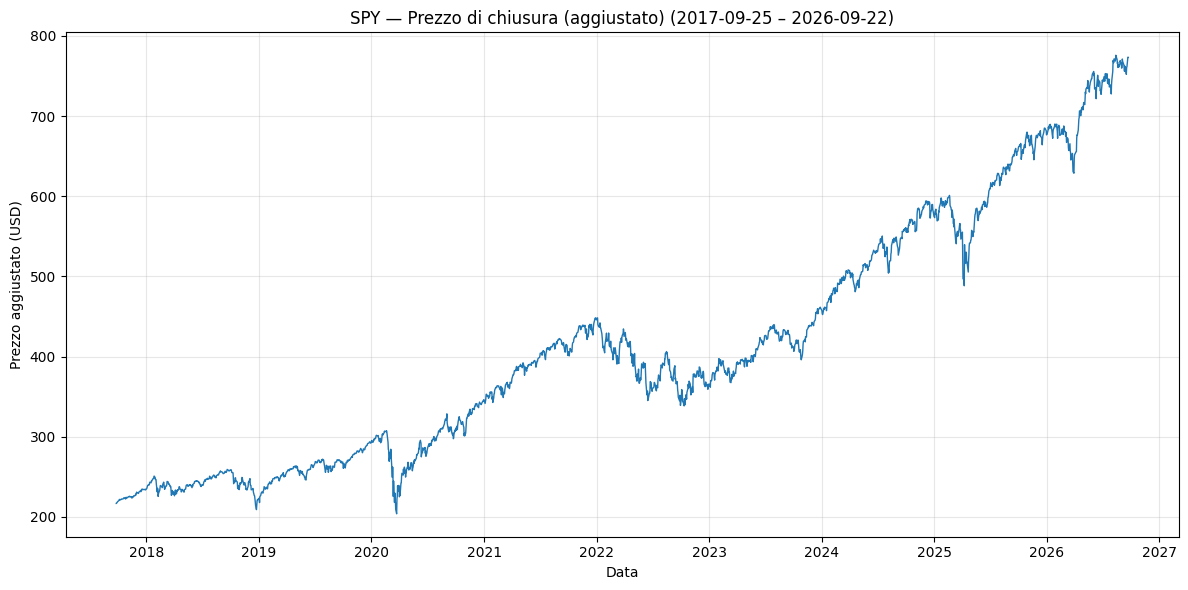

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(prices.index, prices['adj_close'], linewidth=1)
plt.title(f"{TICKER} — Prezzo di chiusura (aggiustato) "
          f"({prices.index.min().date()} – {prices.index.max().date()})")
plt.xlabel("Data")
plt.ylabel("Prezzo aggiustato (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Riepilogo finale
Riepilogo: quante righe abbiamo, il range di date coperto, e cosa è successo con eventuali valori mancanti.

In [7]:
print("=" * 90)
print("SUMMARY: Dati", TICKER)
print("=" * 90)
print(f"Numero di righe (giorni di trading): {len(prices)}")
print(f"Range di date: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"NaN trovati nella serie originale: {n_nan_before}")
print(f"NaN dopo pulizia (ffill/bfill): {n_nan_after}")
print(f"Giorni lavorativi mancanti vs calendario continuo: {len(missing_bdays)} "
      f"(festivita' di borsa, atteso)")
print("-" * 90)


SUMMARY: Dati SPY
Numero di righe (giorni di trading): 2260
Range di date: 2017-09-25 -> 2026-09-22
NaN trovati nella serie originale: 0
NaN dopo pulizia (ffill/bfill): 0
Giorni lavorativi mancanti vs calendario continuo: 87 (festivita' di borsa, atteso)
------------------------------------------------------------------------------------------


# 2: Feature Engineering
Calcoliamo log return giornalieri e volatilità
rolling a 20 giorni, le feature che useremo per l'HMM.


In [8]:
import numpy as np


### Log return giornalieri
Perché log returns:

(1) additivi nel tempo (la somma di log return = log return cumulato)

(2) proprietà statistiche più stabili nel tempo rispetto al prezzo


In [9]:
# log_return_t = log(P_t) - log(P_t-1) = log(P_t / P_t-1)
prices['log_return'] = np.log(prices['adj_close'] / prices['adj_close'].shift(1))

prices[['adj_close', 'log_return']].head()


Price,adj_close,log_return
date,,
2017-09-25,216.88675,NaN
2017-09-26,217.01741,0.00060
2017-09-27,217.86258,0.00389
2017-09-28,218.12393,0.00120
2017-09-29,218.89066,0.00351


### Volatilità rolling (finestra 20 giorni)
Deviazione standard rolling dei log return su 20 giorni di trading (1 mese).


In [10]:
ROLLING_WINDOW = 20  # giorni di trading

prices['volatility_20d'] = prices['log_return'].rolling(window=ROLLING_WINDOW).std()

prices[['log_return', 'volatility_20d']].tail()


Price,log_return,volatility_20d
date,,
2026-09-16,-0.00442,0.00545
2026-09-17,0.01127,0.00606
2026-09-18,0.00129,0.00577
2026-09-21,0.01539,0.00667
2026-09-22,-0.00016,0.00662


### NaN introdotti dal calcolo rolling
1 NaN in log_return (primo giorno) e 20 in volatility_20d (finestra incompleta):
strutturali e attesi, li rimuoviamo con dropna mirato invece di riempirli.


In [11]:
n_nan_return = int(prices['log_return'].isna().sum())
n_nan_vol = int(prices['volatility_20d'].isna().sum())

print(f"NaN in log_return:     {n_nan_return}  (atteso: 1)")
print(f"NaN in volatility_20d: {n_nan_vol}  (atteso: {ROLLING_WINDOW })")

features = prices.dropna(subset=['log_return', 'volatility_20d']).copy()

print(f"\nRighe prima della pulizia: {len(prices)}")
print(f"Righe dopo la pulizia:    {len(features)}")
print(f"NaN residui in features:  {int(features[['log_return', 'volatility_20d']].isna().sum().sum())}")


NaN in log_return:     1  (atteso: 1)
NaN in volatility_20d: 20  (atteso: 20)

Righe prima della pulizia: 2260
Righe dopo la pulizia:    2240
NaN residui in features:  0


### Plot: prezzo, rendimenti e volatilità allineati nel tempo


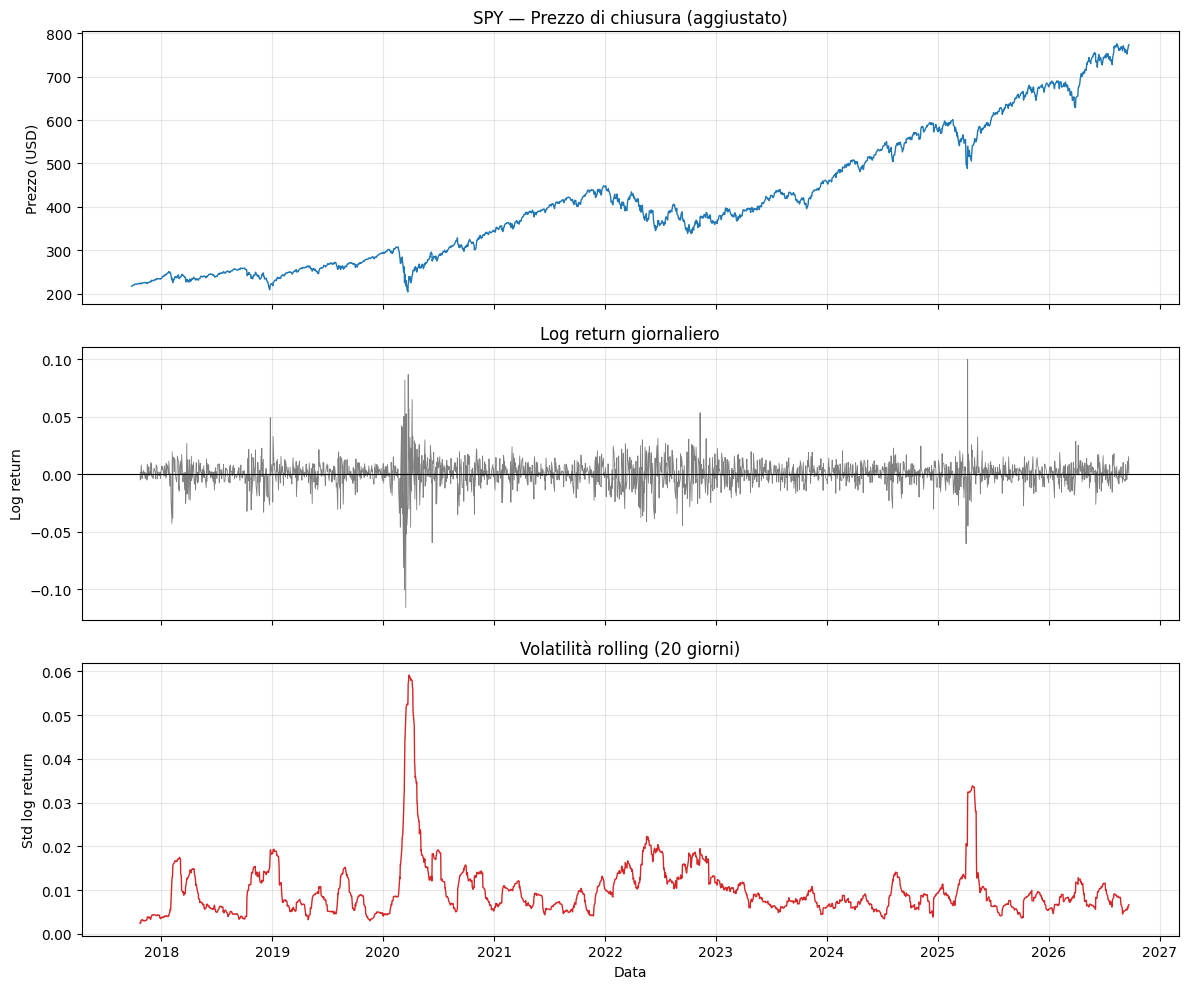

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(prices.index, prices['adj_close'], linewidth=1, color='tab:blue')
axes[0].set_title(f"{TICKER} — Prezzo di chiusura (aggiustato)")
axes[0].set_ylabel("Prezzo (USD)")
axes[0].grid(alpha=0.3)

axes[1].plot(features.index, features['log_return'], linewidth=0.6, color='tab:gray')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title("Log return giornaliero")
axes[1].set_ylabel("Log return")
axes[1].grid(alpha=0.3)

axes[2].plot(features.index, features['volatility_20d'], linewidth=1, color='tab:red')
axes[2].set_title(f"Volatilità rolling ({ROLLING_WINDOW} giorni)")
axes[2].set_ylabel("Std log return")
axes[2].set_xlabel("Data")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Riepilogo statistico finale


In [13]:
print("=" * 40)
print("SUMMARY: Feature Engineering")
print("=" * 40)
print(f"Righe finali (dopo pulizia NaN): {len(features)}")
print(f"Range di date: {features.index.min().date()} -> {features.index.max().date()}")
print("-" * 40)
print("Log return giornaliero:")
print(features['log_return'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)
print(f"Volatilità rolling ({ROLLING_WINDOW}gg):")
print(features['volatility_20d'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)


SUMMARY: Feature Engineering
Righe finali (dopo pulizia NaN): 2240
Range di date: 2017-10-23 -> 2026-09-22
----------------------------------------
Log return giornaliero:
mean    0.00055
std     0.01189
min    -0.11589
max     0.09986
Name: log_return, dtype: float64
----------------------------------------
Volatilità rolling (20gg):
mean   0.00995
std    0.00660
min    0.00241
max    0.05917
Name: volatility_20d, dtype: float64
----------------------------------------


# 3: Hidden Markov Model

Fittiamo un Gaussian HMM a 2 stati sulle feature (log return e volatilità rolling) per identificare i regimi di mercato.

Versione semplicistica: fit su tutta la storia in un colpo solo, il lookahead bias verrà rimosso nella successivamente(walk-forward).


In [14]:
# Installazione di hmmlearn
!pip install -q hmmlearn

# Import per l'HMM
from hmmlearn.hmm import GaussianHMM


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 2.5 MB/s eta 0:00:00


## Preparazione della matrice di feature
Costruisco la matrice di input per l'HMM usando rendimento log e volatilità rolling, e fisso il numero di stati nascosti a 2, per semplicità, senza assumere che sia il numero ottimale.

Le due feature vengono standardizzate (z-score) poichè hanno varianze molto piccole, dell'ordine di 1e-4 e 1e-5, senza standardizzazione la regolarizzazione di default delle covarianze di hmmlearn distorcerebbe le stime.

Qui media e deviazione standard sono calcolate su tutta la serie, cosa accettabile solo perché il fit (semplicistico) è già in-sample: nel walk-forward si useranno quelle del solo training.


In [15]:
# Numero di stati nascosti
N_STATES = 2

# Matrice di feature per l'HMM: rendimento log e volatilità rolling
X_raw = features[['log_return', 'volatility_20d']].values

# Standardizzazione (z-score) con media e std di TUTTA la serie: va bene solo
# per il fit naive, già in-sample. Nel walk-forward si usano quelle del training.
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)


## Fit del Gaussian HMM
Fitto l'HMM su tutta la serie storica in un colpo solo. Versione semplicistica con lookahead bias: verrà sistemata più avanti con un approccio walk-forward.


In [16]:
# Fit del Gaussian HMM
# covariance_type='full' per permettere di vedere la correlazione tra le due feature
# random_state fisso per riproducibilità
np.random.seed(42)
model = GaussianHMM(
    n_components=N_STATES,
    covariance_type='full',
    n_iter=1000,
    random_state=42
)
model.fit(X)

# Non usiamo monitor_.converged: in hmmlearn, a fit concluso, vale sempre True.
# Se viene raggiunto il limite massimo di iterazioni, occorre verificare ulteriormente la convergenza.
print(f"Iterazioni EM usate: {model.monitor_.iter} su 1000")
print(f"Log-likelihood finale: {model.score(X):.2f}")   # utile come diagnostica, non sufficiente da sola per confrontare modelli con diverse complessità
print("\nMatrice di transizione (persistenza degli stati):")
print(model.transmat_)


Iterazioni EM usate: 16 su 1000
Log-likelihood finale: -4279.64

Matrice di transizione (persistenza degli stati):
[[0.99084777 0.00915223]
 [0.01918182 0.98081818]]


## Estrazione della sequenza di stati
Estraggo, per ogni giorno, lo stato nascosto predetto dal modello.


In [17]:
# Sequenza di stati predetti, uno per ogni giorno
hidden_states = model.predict(X)
features['hmm_state'] = hidden_states
display(features[['adj_close', 'log_return', 'volatility_20d', 'hmm_state']].head(5))

print(f"\nPrimi valori con stato = 1:")
mask = features['hmm_state'] == 1
stati_1 = features[mask]
display(stati_1[['adj_close', 'log_return', 'volatility_20d', 'hmm_state']].head(5))



Price,adj_close,log_return,volatility_20d,hmm_state
date,,,,
2017-10-23,223.14253,-0.00390,0.00241,0
2017-10-24,223.53455,0.00176,0.00241,0
2017-10-25,222.42801,-0.00496,0.00273,0
2017-10-26,222.71559,0.00129,0.00273,0
2017-10-27,224.53651,0.00814,0.00312,0



Primi valori con stato = 1:


Price,adj_close,log_return,volatility_20d,hmm_state
date,,,,
2018-02-02,241.21968,-0.02201,0.00763,1
2018-02-05,231.13124,-0.04272,0.01221,1
2018-02-06,235.68513,0.01951,0.01309,1
2018-02-07,234.40657,-0.00544,0.01311,1
2018-02-08,225.61420,-0.03823,0.01550,1


## Visualizzazione: prezzo colorato per stato HMM
Plotto il prezzo aggiustato colorando lo sfondo in base allo stato predetto in quel giorno, per verificare a occhio se gli stati coincidono con periodi sensati (es. 2020, 2022).


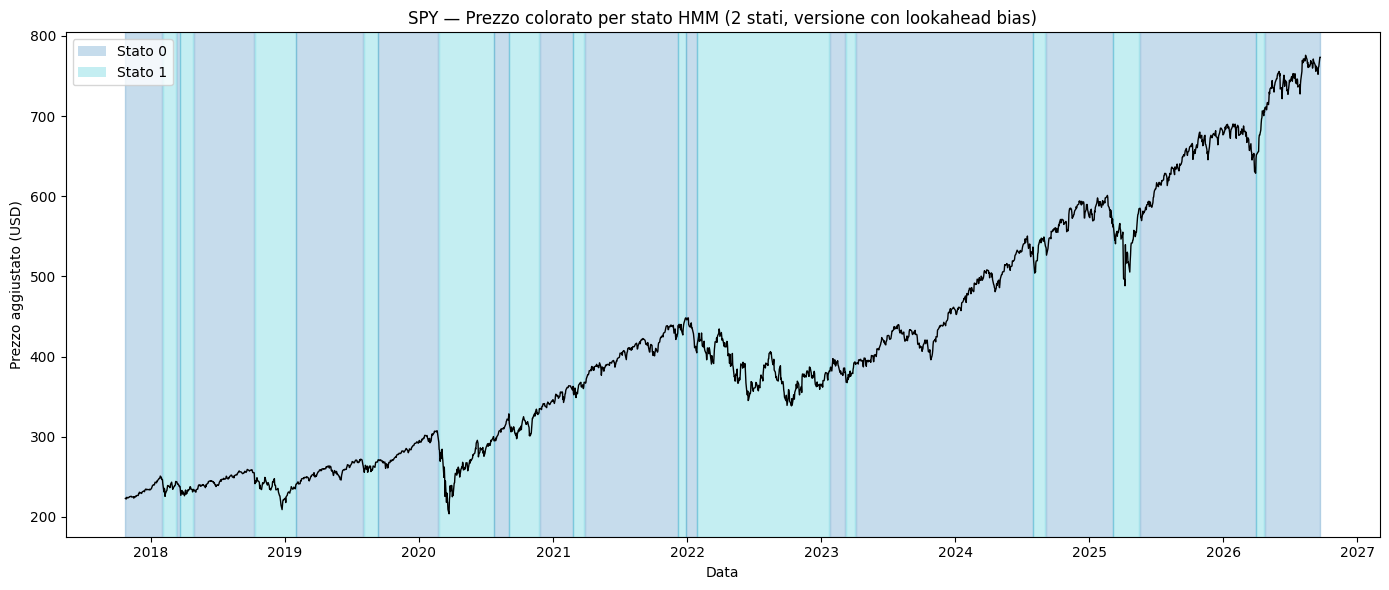

In [18]:
# Plot del prezzo con sfondo colorato in base allo stato HMM predetto
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(14, 6))
cmap = plt.get_cmap('tab10', N_STATES)

# Coloriamo lo sfondo per ogni tratto contiguo dello stesso stato
state_changes = features['hmm_state'].ne(features['hmm_state'].shift()).cumsum()
for _, segment in features.groupby(state_changes):
    state = segment['hmm_state'].iloc[0]
    ax.axvspan(segment.index[0], segment.index[-1], color=cmap(state), alpha=0.25)

ax.plot(features.index, features['adj_close'], color='black', linewidth=1)
ax.set_title(f"{TICKER} — Prezzo colorato per stato HMM "
             f"({N_STATES} stati, versione con lookahead bias)")
ax.set_xlabel("Data")
ax.set_ylabel("Prezzo aggiustato (USD)")

legend_elements = [Patch(facecolor=cmap(s), alpha=0.25, label=f"Stato {s}") for s in range(N_STATES)]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()


## Caratteristiche degli stati
Calcolo media e deviazione standard dei rendimenti, e volatilità media, per ciascuno stato, per assegnare un'etichetta intuitiva.

Le etichette numeriche 0/1 sono arbitrarie: è questa tabella a dire cosa rappresentano davvero.


In [19]:
# Caratteristiche di ciascuno stato, per assegnare un'etichetta intuitiva
print("=" * 100)
print(f"CARATTERISTICHE DEGLI STATI HMM ({N_STATES} stati, versione semplicistica)")
print("=" * 100)

state_stats = features.groupby('hmm_state').agg(
    n_giorni=('log_return', 'count'),
    return_medio=('log_return', 'mean'),
    return_std=('log_return', 'std'),
    volatilita_media=('volatility_20d', 'mean')
)

print(state_stats)
print("-" * 100)


CARATTERISTICHE DEGLI STATI HMM (2 stati, versione semplicistica)
           n_giorni  return_medio  return_std  volatilita_media
hmm_state                                                      
0              1527       0.00073     0.00710           0.00697
1               713       0.00017     0.01834           0.01635
----------------------------------------------------------------------------------------------------


# 4: Regola di Trading Condizionata al Regime e Backtest semplicistico

Obiettivo: usare la sequenza hmm_state calcolata in precedenza per costruire una regola di trading semplice, calcolarne i rendimenti in modo corretto (senza lookahead nello shift), e confrontare l'equity curve della strategia con quella di buy-and-hold.

**Ricordo:** l'HMM (per ora) è stato fittato in un colpo solo su tutta la storia dei prezzi.

Questo significa che lo stato assegnato a un giorno qualsiasi t è stato calcolato dal modello conoscendo anche l'andamento futuro rispetto a t.

È un lookahead bias a tutti gli effetti, distinto da quello dello shift che gestiamo più sotto, e rende i risultati di questa parte ottimistici.

Successivamente, mediante un HMM rifittato progressivamente in stile walk-forward (usando solo dati disponibili fino a quel momento), verrà mostrata una stima più realistica.


### Identificazione dinamica dello stato "calmo"

Conviene identificare lo stato calmo/rialzista dinamicamente invece di hardcodare state == 0, per due motivi:

(1) l'etichetta numerica che l'HMM assegna a ciascuno stato (0 o 1) è arbitraria: dipende dall'inizializzazione interna dell'algoritmo, non dal suo significato economico.
Anche fissando random_state, un nuovo download dei dati, una finestra temporale diversa o un aggiornamento di hmmlearn possono far sì che ciò che oggi è "stato 0" domani sia "stato 1".

(2) nel Blocco 5 rifitteremo l'HMM molte volte in modalità walk-forward: a ogni refit le etichette possono rimescolarsi in modo indipendente dal refit precedente.
Se la regola fosse hardcodata su position = 1 if state == 0, rischieremmo silenziosamente di investire nello stato sbagliato in una parte dei refit.

Utilizziamo state_stats per identificare come regime "calmo" lo stato con rendimento medio più elevato, verificando successivamente che presenti anche la volatilità media più bassa.

Se i due criteri non coincidono, l'ipotesi economica alla base della strategia non risulta confermata dai dati. In questo caso, preferiamo non applicare la regola di trading, anziché selezionare arbitrariamente uno stato.


In [20]:
# Identifichiamo dinamicamente lo stato "calmo" e quello "volatile" usando
# state_stats, invece di hardcodare gli indici 0/1
calm_state = state_stats['return_medio'].idxmax()
volatile_state = state_stats['return_medio'].idxmin()

print(f"Stato identificato come 'calmo/rialzista':     {calm_state} "
      f"(return medio = {state_stats.loc[calm_state, 'return_medio']:.5f}, "
      f"volatilita' media = {state_stats.loc[calm_state, 'volatilita_media']:.5f})")
print(f"Stato identificato come 'volatile/ribassista':  {volatile_state} "
      f"(return medio = {state_stats.loc[volatile_state, 'return_medio']:.5f}, "
      f"volatilita' media = {state_stats.loc[volatile_state, 'volatilita_media']:.5f})")

# Controllo di coerenza: lo stato con return medio piu' alto dovrebbe avere
# anche volatilita' media piu' bassa. In caso contrario i due stati non sono
# nettamente separabili in "calmo" vs "volatile".
if state_stats.loc[calm_state, 'volatilita_media'] >= state_stats.loc[volatile_state, 'volatilita_media']:
    print("\nATTENZIONE: lo stato con return medio piu' alto NON ha volatilita' piu' bassa.")
    print("La distinzione calmo/volatile e' meno netta del previsto: rivedere l'interpretazione.")
else:
    print("\nCoerenza confermata: lo stato 'calmo' ha sia return medio piu' alto sia volatilita' piu' bassa.")


Stato identificato come 'calmo/rialzista':     0 (return medio = 0.00073, volatilita' media = 0.00697)
Stato identificato come 'volatile/ribassista':  1 (return medio = 0.00017, volatilita' media = 0.01635)

Coerenza confermata: lo stato 'calmo' ha sia return medio piu' alto sia volatilita' piu' bassa.


### Regola di posizione

Posizione binaria e senza leva: 100% investiti nei giorni in cui lo stato è quello identificato come calmo, 0% / cash altrimenti.

Nessuno short.


In [21]:
# Posizione giornaliera basata sullo stato HMM: 1 = investiti, 0 = cash
features['position'] = np.where(features['hmm_state'] == calm_state, 1, 0)

features[['hmm_state', 'position']].head(10)


Price,hmm_state,position
date,,
2017-10-23,0,1
2017-10-24,0,1
2017-10-25,0,1
2017-10-26,0,1
2017-10-27,0,1
2017-10-30,0,1
2017-10-31,0,1
2017-11-01,0,1
2017-11-02,0,1


### Rendimento della strategia: perché serve lo shift di un giorno

Il rendimento della strategia nel giorno t viene calcolato utilizzando la posizione del giorno precedente, attraverso position.shift(1).

Senza lo shift, utilizzeremmo il segnale del giorno t per calcolare il rendimento dello stesso giorno, introducendo un ulteriore look-ahead bias.

Lo shift(1) non elimina il look-ahead bias dell'HMM addestrato sull'intera serie storica e non rappresenta una simulazione realistica dell'esecuzione degli ordini. Questo backtest rimane quindi preliminare (*naive*).

In [22]:
# Rendimento giornaliero della strategia = rendimento del giorno x posizione
# decisa il giorno PRECEDENTE (shift di un giorno sulla colonna position)
features['strategy_log_return'] = features['log_return'] * features['position'].shift(1)

# Il primo giorno non ha una posizione precedente definita: lo trattiamo come cash
features['strategy_log_return'] = features['strategy_log_return'].fillna(0)

features[['log_return', 'position', 'strategy_log_return']].head(10)


Price,log_return,position,strategy_log_return
date,,,
2017-10-23,-0.00390,1,0.00000
2017-10-24,0.00176,1,0.00176
2017-10-25,-0.00496,1,-0.00496
2017-10-26,0.00129,1,0.00129
2017-10-27,0.00814,1,0.00814
2017-10-30,-0.00373,1,-0.00373
2017-10-31,0.00156,1,0.00156
2017-11-01,0.00132,1,0.00132
2017-11-02,0.00039,1,0.00039


### Equity curve: strategia vs buy-and-hold

Poiché i log return sono additivi nel tempo, l'equity curve si ottiene sommando cumulativamente i log return e riportando il risultato in scala "prezzo" con l'esponenziale.


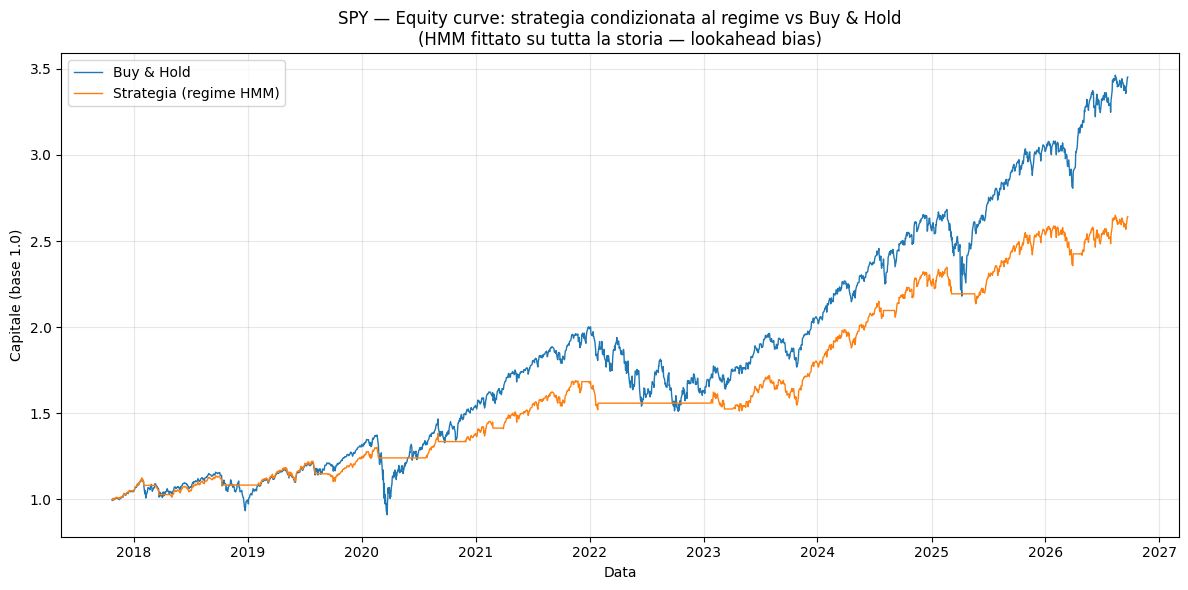

In [23]:
# Equity curve (capitale base 1.0) per strategia e buy-and-hold
features['equity_strategy'] = np.exp(features['strategy_log_return'].cumsum())
features['equity_buy_hold'] = np.exp(features['log_return'].cumsum())

plt.figure(figsize=(12, 6))
plt.plot(features.index, features['equity_buy_hold'], label='Buy & Hold', color='tab:blue', linewidth=1)
plt.plot(features.index, features['equity_strategy'], label='Strategia (regime HMM)', color='tab:orange', linewidth=1)
plt.title(f"{TICKER} — Equity curve: strategia condizionata al regime vs Buy & Hold\n"
          f"(HMM fittato su tutta la storia — lookahead bias)")
plt.xlabel("Data")
plt.ylabel("Capitale (base 1.0)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Metriche di performance

Calcoliamo, per entrambe le serie:

(1) rendimento cumulato totale

(2) CAGR

(3) volatilità annualizzata

(4) Sharpe ratio, con risk-free rate assunto a 0 per semplicità

(5) drawdown massimo


In [24]:
def compute_metrics(log_returns, periods_per_year=252):
    """
    Calcola le metriche a partire dai log return giornalieri di una serie.
    """
    equity_curve = np.exp(log_returns.cumsum())

    # Prependiamo il capitale iniziale (1.0, prima del primo giorno) cosi'
    # il drawdown viene calcolato correttamente anche rispetto al punto di partenza
    equity_with_start = pd.concat([pd.Series([1.0]), equity_curve.reset_index(drop=True)],ignore_index=True)

    n_days = len(log_returns)
    years = n_days / periods_per_year

    total_return = equity_curve.iloc[-1] - 1
    cagr = equity_curve.iloc[-1] ** (1 / years) - 1
    ann_vol = log_returns.std() * np.sqrt(periods_per_year)
    ann_log_return = log_returns.mean() * periods_per_year
    sharpe = ann_log_return / ann_vol if ann_vol > 0 else np.nan

    running_max = equity_with_start.cummax()
    drawdown = equity_with_start / running_max - 1
    max_drawdown = drawdown.min()

    return {
        'Rendimento cumulato totale': total_return,
        'CAGR': cagr,
        "Volatilita' annualizzata": ann_vol,
        'Sharpe ratio (rf=0)': sharpe,
        'Max drawdown': max_drawdown
    }

metrics_strategy = compute_metrics(features['strategy_log_return'])
metrics_buy_hold = compute_metrics(features['log_return'])

summary_df = pd.DataFrame({
    'Strategia (regime HMM)': metrics_strategy,
    'Buy & Hold': metrics_buy_hold
})

summary_df


,Strategia (regime HMM),Buy & Hold
Rendimento cumulato totale,1.64086,2.45238
CAGR,0.11544,0.14958
Volatilita' annualizzata,0.09836,0.18878
Sharpe ratio (rf=0),1.11067,0.73839
Max drawdown,-0.10437,-0.33717


### Riepilogo finale


In [25]:
print("=" * 50)
print("SUMMARY: Trading Rule e Backtest semplicistico")
print("=" * 50)
print(f"Stato 'calmo' (posizione long):     {calm_state}")
print(f"Stato 'volatile' (posizione cash):   {volatile_state}")
print("-" * 65)

print(summary_df)
print("-" * 65)

pct_days_invested = features['position'].mean() * 100
print(f"Giorni investiti: {pct_days_invested:.1f}% del periodo")
print("-" * 90)
print("LOOKAHEAD BIAS:")
print("- Questo backtest usa la sequenza di stati prodotta dall'HMM fittato su tutta la storia")
print("- I risultati qui sopra sono probabilmente ottimistici e non vanno interpretati come")
print("  performance realistiche della strategia.")
print("- Successivamente, con il walk-forward, verrà risolto il lookahead bias e verrà data")
print("  una stima piu' realistica.")
print("=" * 90)


SUMMARY: Trading Rule e Backtest semplicistico
Stato 'calmo' (posizione long):     0
Stato 'volatile' (posizione cash):   1
-----------------------------------------------------------------
                            Strategia (regime HMM)  Buy & Hold
Rendimento cumulato totale                 1.64086     2.45238
CAGR                                       0.11544     0.14958
Volatilita' annualizzata                   0.09836     0.18878
Sharpe ratio (rf=0)                        1.11067     0.73839
Max drawdown                              -0.10437    -0.33717
-----------------------------------------------------------------
Giorni investiti: 68.2% del periodo
------------------------------------------------------------------------------------------
LOOKAHEAD BIAS:
- Questo backtest usa la sequenza di stati prodotta dall'HMM fittato su tutta la storia
- I risultati qui sopra sono probabilmente ottimistici e non vanno interpretati come
  performance realistiche della strategia.
- Succe